The main objective of this activity is to provide an initial experience trying different optimization strategies. We'll train a Neural Network to identify the numbers of MNIST dataset. The students will assess the convergence of the network using different optimizers parameters.

In [12]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

In [13]:
(x_train,y_train), (x_test,y_test)= tf.keras.datasets.mnist.load_data()
x_train = np.reshape(x_train, (-1, 784))
x_test = np.reshape(x_test, (-1, 784))

In [14]:
num_classes = 10
# Dataset normalization
x_train = x_train.astype('float32')
x_test = x_test.astype('float32')
x_train= x_train/255.
x_test = x_test/255.
# One-hot encoding
y_train_h = np.zeros((np.size(y_train,0) , num_classes))
y_test_h = np.zeros((np.size(y_test,0) , num_classes))
for i in range(np.size(y_train , 0)):
  y_train_h[i , y_train[i]] = 1

for i in range(np.size(y_test , 0)):
  y_test_h[i , y_test[i]] = 1


Model creation

In [15]:
model = tf.keras.models.Sequential()
model.add(tf.keras.layers.Dense(256, 'sigmoid'))
model.add(tf.keras.layers.Dense(512, 'relu'))
model.add(tf.keras.layers.Dense(256, 'relu'))
model.add(tf.keras.layers.Dense(10, 'sigmoid'))

In [16]:
#inputs = tf.keras.Input(shape=(784,))
#x = tf.keras.layers.Dense(256, activation="relu")(inputs)
#x = tf.keras.layers.Dense(512, activation="relu")(x)
#x = tf.keras.layers.Dense(256, activation="relu")(x)
#outputs = tf.keras.layers.Dense(10, activation="sigmoid")(x)
#model = tf.keras.Model(inputs=inputs, outputs=outputs)

In [ ]:
lr = 0.0001
momentum = 0.01
nest = False

optimizer = tf.keras.optimizers.Adam(learning_rate=lr)
loss = tf.keras.losses.CategoricalCrossentropy()
metrics = ['accuracy']

batch_size = 128
epochs = 50

In [18]:
model.compile(
    optimizer=optimizer,
    loss = loss,
    metrics = metrics
)

In [19]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    patience=10,
    verbose=1,
    mode='max',
    restore_best_weights=True,
)
callbacks = [early_stop]

In [20]:
history = model.fit(
    x = x_train,
    y = y_train_h,
    batch_size = batch_size,
    epochs = epochs,
    validation_split = 0.2,
    callbacks = callbacks
)

Epoch 1/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.7323 - loss: 1.1086 - val_accuracy: 0.8813 - val_loss: 0.4557
Epoch 2/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8931 - loss: 0.3881 - val_accuracy: 0.9101 - val_loss: 0.3181
Epoch 3/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9089 - loss: 0.3135 - val_accuracy: 0.9190 - val_loss: 0.2825
Epoch 4/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9181 - loss: 0.2803 - val_accuracy: 0.9268 - val_loss: 0.2561
Epoch 5/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9238 - loss: 0.2584 - val_accuracy: 0.9303 - val_loss: 0.2373
Epoch 6/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9299 - loss: 0.2400 - val_accuracy: 0.9345 - val_loss: 0.2236
Epoch 7/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9337 - loss: 0.2256 - val_accuracy: 0.9376 - val_loss: 0.2139
Epoch 8/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9376 - loss: 0.2111 - val_accuracy: 0.

In [21]:
model.evaluate(
    x = x_test,
    y = y_test_h
)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9757 - loss: 0.0814


[0.08135697990655899, 0.9757000207901001]

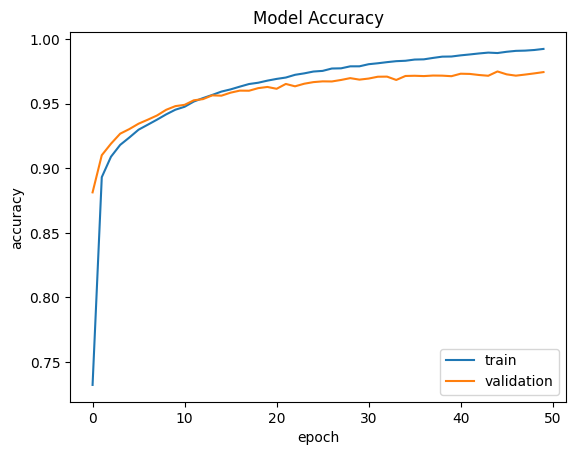

In [22]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='lower right')
plt.show()

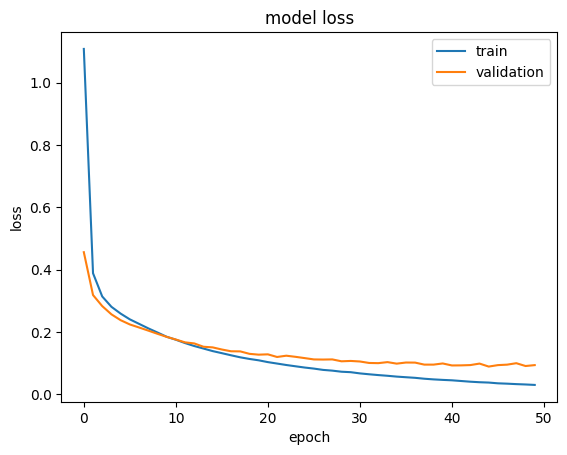

In [23]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper right')
plt.show()

## Exercise:

Try other training parameters, following this table.

---

Student | Optimizer | Learning Rate
--------|------------|---------
Student 1            |SGD                | 0.01
Student 2    |SGD+Momentum       | 0.01
Student 3             |Nesterov Momentum  | 0.01
Student 4       |Adagrad            | 0.01
Student 5                        |RMSProp            | 0.01
Student 6               |Adam               | 0.01
Student 7                           |Adam               | 0.0001
Student 8             |Adam               | 0.1

---

Register your results in [here](https://docs.google.com/spreadsheets/d/1KjptUtmX8cSWZi7Z27zxCMs7TjZfhwAXCFiCXPNFMAk/edit?usp=sharing).